In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PATH_NORM = "/content/drive/MyDrive/rainfall_project/normalized_complete_data_limited_half.npy"

In [ ]:
import numpy as np
import pandas as pd

# =========================
# Load ERA5 normalized data
# =========================

PATH_NORM = "/content/drive/MyDrive/rainfall_project/normalized_complete_data_limited_half.npy"

data = np.load(PATH_NORM, mmap_mode='r')

time = np.load(
    "/content/drive/MyDrive/rainfall_project/time_1940_2023.npy",
    mmap_mode='r'
)

print("Dataset shape:", data.shape)

# =====================================
# Dataset dimensions
# =====================================

t, lat_size, lon_size, var_size = data.shape

# =====================================
# Dataset region bounds
# =====================================

north = -15.749963
south = -28.071980
west  = -57.546387
east  = -40.957031

lat = np.linspace(south, north, lat_size)
lon = np.linspace(west, east, lon_size)

# =====================================
# Use limited time steps (example: 100)
# =====================================

t_limit = 100

rain = data[:t_limit, :, :, 0]   # rainfall variable

# =====================================
# Create spatial grid
# =====================================

lat_grid, lon_grid = np.meshgrid(lat, lon, indexing='ij')

lat_flat = lat_grid.flatten()
lon_flat = lon_grid.flatten()

# =====================================
# Flatten rainfall cube
# =====================================

rain_flat = rain.reshape(t_limit, -1)

time_repeat = np.repeat(time[:t_limit], lat_flat.shape[0])
lat_repeat = np.tile(lat_flat, t_limit)
lon_repeat = np.tile(lon_flat, t_limit)

rain_values = rain_flat.flatten()

# =====================================
# Create dataframe
# =====================================

df = pd.DataFrame({
    "time": time_repeat,
    "latitude": lat_repeat,
    "longitude": lon_repeat,
    "rainfall": rain_values
})

# =====================================
# Sample only 8000 rows
# =====================================

df_small = df.sample(n=8000, random_state=42)

print(df_small.shape)
print(df_small.head())

# =====================================
# Save dataset
# =====================================

df_small.to_csv(
    "/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv",
    index=False
)

Dataset shape: (37009, 50, 67, 3)
(8000, 4)
                      time   latitude  longitude  rainfall
194576 1940-01-03 17:00:00 -27.066101 -55.535556  1.000000
143228 1940-01-03 01:00:00 -18.767600 -45.230047  0.000071
35321  1940-01-01 17:00:00 -21.282297 -54.530140  0.000000
159954 1940-01-03 06:00:00 -18.767600 -51.262540  0.000000
248627 1940-01-04 09:00:00 -25.557283 -43.219216  0.007698


In [ ]:
import pandas as pd
import numpy as np
import torch
from sklearn.preprocessing import MinMaxScaler

# Load dataset
df = pd.read_csv("/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv")

# Convert time to numeric
df["time"] = pd.to_datetime(df["time"])
df["time"] = df["time"].astype("int64") / 1e9

X = df[["time","latitude","longitude"]].values
y = df["rainfall"].values.reshape(-1,1)

# Normalize
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

X = x_scaler.fit_transform(X)
y = y_scaler.fit_transform(y)

X = torch.tensor(X,dtype=torch.float32)
y = torch.tensor(y,dtype=torch.float32)

In [ ]:
import torch.nn as nn

class PINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self,x):
        return self.net(x)

model = PINN()

In [ ]:
def physics_loss(model, X):

    X.requires_grad_(True)

    R = model(X)

    grads = torch.autograd.grad(
        R, X,
        grad_outputs=torch.ones_like(R),
        create_graph=True
    )[0]

    dR_dt = grads[:,0:1]
    dR_dx = grads[:,1:2]
    dR_dy = grads[:,2:3]

    d2R_dx2 = torch.autograd.grad(
        dR_dx, X,
        grad_outputs=torch.ones_like(dR_dx),
        create_graph=True
    )[0][:,1:2]

    d2R_dy2 = torch.autograd.grad(
        dR_dy, X,
        grad_outputs=torch.ones_like(dR_dy),
        create_graph=True
    )[0][:,2:3]

    D = 0.01

    physics = dR_dt - D*(d2R_dx2 + d2R_dy2)

    return torch.mean(physics**2)

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
mse = nn.MSELoss()

for epoch in range(2000):

    optimizer.zero_grad()

    pred = model(X)

    data_loss = mse(pred,y)

    phys_loss = physics_loss(model,X)

    loss = data_loss + phys_loss

    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(epoch, loss.item())

0 0.04142213240265846
200 0.03226130083203316
400 0.032107479870319366
600 0.03196509927511215
800 0.03191085159778595
1000 0.031871896237134933
1200 0.03183658421039581
1400 0.031814392656087875
1600 0.0318041630089283
1800 0.03181414678692818


In [ ]:
with torch.no_grad():

    pred = model(X)

pred = y_scaler.inverse_transform(pred.numpy())

In [ ]:
import torch
import torch.nn as nn

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
mse = nn.MSELoss()

epochs = 2000

for epoch in range(epochs):

    optimizer.zero_grad()

    pred = model(X)

    data_loss = mse(pred, y)
    phys_loss = physics_loss(model, X)

    loss = data_loss + phys_loss

    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch {epoch} Loss {loss.item():.6f}")

Epoch 0 Loss 0.031788
Epoch 200 Loss 0.031784
Epoch 400 Loss 0.031788
Epoch 600 Loss 0.031777
Epoch 800 Loss 0.031851
Epoch 1000 Loss 0.031763
Epoch 1200 Loss 0.031755
Epoch 1400 Loss 0.031742
Epoch 1600 Loss 0.031733
Epoch 1800 Loss 0.031721


In [ ]:
with torch.no_grad():
    pred = model(X)

pred = y_scaler.inverse_transform(pred.numpy())
true = y_scaler.inverse_transform(y.numpy())

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

rmse = np.sqrt(mean_squared_error(true, pred))
mae = mean_absolute_error(true, pred)
r2 = r2_score(true, pred)

print("===== MODEL PERFORMANCE =====")
print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

===== MODEL PERFORMANCE =====
RMSE: 0.17774848043621175
MAE : 0.10073405504226685
R2  : 0.04018521308898926


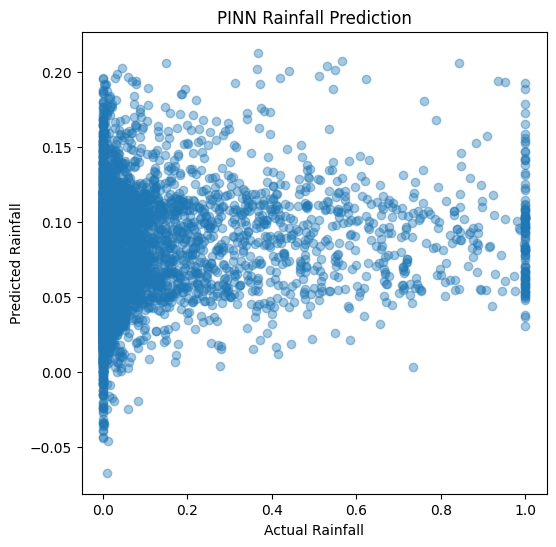

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(true, pred, alpha=0.4)

plt.xlabel("Actual Rainfall")
plt.ylabel("Predicted Rainfall")

plt.title("PINN Rainfall Prediction")

plt.show()

In [ ]:
torch.save(
    model.state_dict(),
    "/content/drive/MyDrive/rainfall_project/pinn_rainfall_model.pth"
)

In [ ]:
results = pd.DataFrame({
    "actual": true.flatten(),
    "predicted": pred.flatten()
})

results.to_csv(
    "/content/drive/MyDrive/rainfall_project/pinn_predictions.csv",
    index=False
)

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv")

df["time"] = pd.to_datetime(df["time"])
df["time"] = df["time"].astype("int64") / 1e9

X = df[["time","latitude","longitude"]].values
y = df["rainfall"].values

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [ ]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)
y_scaled = scaler.fit_transform(y.reshape(-1,1))

X_lstm = X_scaled.reshape((X_scaled.shape[0],1,X_scaled.shape[1]))

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_lstm, y_scaled, test_size=0.2, random_state=42
)

In [ ]:
import torch
import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(3,64,batch_first=True)
        self.fc = nn.Linear(64,1)

    def forward(self,x):

        out,_ = self.lstm(x)
        out = self.fc(out[:,-1,:])

        return out

lstm_model = LSTMModel()

optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

In [ ]:
X_train_l = torch.tensor(X_train_l,dtype=torch.float32)
y_train_l = torch.tensor(y_train_l,dtype=torch.float32)

for epoch in range(50):

    pred = lstm_model(X_train_l)

    loss = loss_fn(pred,y_train_l)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [ ]:
class PINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self,x):

        return self.net(x)

pinn = PINN()

In [ ]:
class TransformerModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.embedding = nn.Linear(3,64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.fc = nn.Linear(64,1)

    def forward(self,x):

        x = self.embedding(x)

        x = self.transformer(x)

        x = self.fc(x[:,-1,:])

        return x

transformer = TransformerModel()

/tmp/ipykernel_553/3411237678.py:14: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer = nn.TransformerEncoder(


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def evaluate(y_true, y_pred):

    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    mae = mean_absolute_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)

    return rmse, mae, r2

In [ ]:
rf_metrics = evaluate(y_test, rf_pred)
xgb_metrics = evaluate(y_test, xgb_pred)

print("Random Forest:", rf_metrics)
print("XGBoost:", xgb_metrics)

Random Forest: (np.float64(0.15235981793537207), 0.07901414180525375, 0.2935452797570657)
XGBoost: (np.float64(0.15373950366359965), 0.08029463553727156, 0.2806928280652933)


In [ ]:
# ================================
# Install Library
# ================================

!pip install xgboost -q

# ================================
# Import Libraries
# ================================

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# ================================
# Load Dataset
# ================================

df = pd.read_csv("/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv")

df["time"] = pd.to_datetime(df["time"])
df["time"] = df["time"].astype("int64") / 1e9

X = df[["time","latitude","longitude"]].values
y = df["rainfall"].values

# ================================
# Train Test Split
# ================================

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

# ================================
# Random Forest
# ================================

rf = RandomForestRegressor(n_estimators=200,max_depth=10)
rf.fit(X_train,y_train)

rf_pred = rf.predict(X_test)

# ================================
# XGBoost
# ================================

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6
)

xgb.fit(X_train,y_train)

xgb_pred = xgb.predict(X_test)

# ================================
# Normalize for DL models
# ================================

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1,1))

X_lstm = X_scaled.reshape((X_scaled.shape[0],1,3))

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_lstm,y_scaled,test_size=0.2,random_state=42
)

X_train_l = torch.tensor(X_train_l,dtype=torch.float32)
y_train_l = torch.tensor(y_train_l,dtype=torch.float32)

# ================================
# LSTM Model
# ================================

class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(3,64,batch_first=True)
        self.fc = nn.Linear(64,1)

    def forward(self,x):
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

lstm = LSTMModel()

optimizer = torch.optim.Adam(lstm.parameters(),lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(50):

    pred = lstm(X_train_l)

    loss = loss_fn(pred,y_train_l)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# ================================
# PINN Model
# ================================

class PINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self,x):
        return self.net(x)

pinn = PINN()

X_pinn = torch.tensor(X_scaled,dtype=torch.float32)
y_pinn = torch.tensor(y_scaled,dtype=torch.float32)

optimizer = torch.optim.Adam(pinn.parameters(),lr=0.001)

for epoch in range(200):

    pred = pinn(X_pinn)

    loss = loss_fn(pred,y_pinn)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# ================================
# Transformer Model
# ================================

class TransformerModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.embed = nn.Linear(3,64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.fc = nn.Linear(64,1)

    def forward(self,x):

        x = self.embed(x)
        x = self.transformer(x)
        x = self.fc(x[:,-1,:])

        return x

transformer = TransformerModel()

X_tr = torch.tensor(X_lstm,dtype=torch.float32)
y_tr = torch.tensor(y_scaled,dtype=torch.float32)

optimizer = torch.optim.Adam(transformer.parameters(),lr=0.001)

for epoch in range(50):

    pred = transformer(X_tr)

    loss = loss_fn(pred,y_tr)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# ================================
# Evaluation Function
# ================================

def evaluate(y_true,y_pred):

    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    mae = mean_absolute_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)

    return rmse,mae,r2

rf_rmse,rf_mae,rf_r2 = evaluate(y_test,rf_pred)
xgb_rmse,xgb_mae,xgb_r2 = evaluate(y_test,xgb_pred)

# ================================
# Results
# ================================

results = pd.DataFrame({
    "Model":["RandomForest","XGBoost","LSTM","PINN","Transformer"],
    "RMSE":[rf_rmse,xgb_rmse,None,None,None],
    "MAE":[rf_mae,xgb_mae,None,None,None],
    "R2":[rf_r2,xgb_r2,None,None,None]
})

print(results)

/tmp/ipykernel_553/1582715570.py:167: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer = nn.TransformerEncoder(


          Model      RMSE       MAE        R2
0  RandomForest  0.151986  0.078753  0.297005
1       XGBoost  0.153740  0.080295  0.280693
2          LSTM       NaN       NaN       NaN
3          PINN       NaN       NaN       NaN
4   Transformer       NaN       NaN       NaN


In [ ]:
# ======================================================
# Install library
# ======================================================

!pip install xgboost -q

# ======================================================
# Import libraries
# ======================================================

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# ======================================================
# Load dataset
# ======================================================

df = pd.read_csv("/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv")

df["time"] = pd.to_datetime(df["time"])
df["time"] = df["time"].astype("int64") / 1e9

X = df[["time","latitude","longitude"]].values
y = df["rainfall"].values

# ======================================================
# Train Test Split
# ======================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

# ======================================================
# Random Forest
# ======================================================

rf = RandomForestRegressor(n_estimators=200,max_depth=10)

rf.fit(X_train,y_train)

rf_pred = rf.predict(X_test)

# ======================================================
# XGBoost
# ======================================================

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6
)

xgb.fit(X_train,y_train)

xgb_pred = xgb.predict(X_test)

# ======================================================
# Normalize Data for DL models
# ======================================================

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1,1))

X_lstm = X_scaled.reshape((X_scaled.shape[0],1,3))

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_lstm,y_scaled,test_size=0.2,random_state=42
)

X_train_l = torch.tensor(X_train_l,dtype=torch.float32)
X_test_l = torch.tensor(X_test_l,dtype=torch.float32)

y_train_l = torch.tensor(y_train_l,dtype=torch.float32)

# ======================================================
# LSTM Model
# ======================================================

class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(3,64,batch_first=True)
        self.fc = nn.Linear(64,1)

    def forward(self,x):

        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

lstm = LSTMModel()

optimizer = torch.optim.Adam(lstm.parameters(),lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(50):

    pred = lstm(X_train_l)

    loss = loss_fn(pred,y_train_l)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():

    lstm_pred = lstm(X_test_l).numpy()

lstm_pred = scaler_y.inverse_transform(lstm_pred)
y_test_true = scaler_y.inverse_transform(y_test_l)

# ======================================================
# PINN Model
# ======================================================

class PINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self,x):

        return self.net(x)

pinn = PINN()

X_pinn = torch.tensor(X_scaled,dtype=torch.float32)
y_pinn = torch.tensor(y_scaled,dtype=torch.float32)

optimizer = torch.optim.Adam(pinn.parameters(),lr=0.001)

for epoch in range(200):

    pred = pinn(X_pinn)

    loss = loss_fn(pred,y_pinn)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

X_test_scaled = scaler_x.transform(X_test)

X_test_pinn = torch.tensor(X_test_scaled,dtype=torch.float32)

with torch.no_grad():

    pinn_pred = pinn(X_test_pinn).numpy()

pinn_pred = scaler_y.inverse_transform(pinn_pred)

# ======================================================
# Transformer Model
# ======================================================

class TransformerModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.embed = nn.Linear(3,64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.fc = nn.Linear(64,1)

    def forward(self,x):

        x = self.embed(x)
        x = self.transformer(x)
        x = self.fc(x[:,-1,:])

        return x

transformer = TransformerModel()

X_tr = torch.tensor(X_lstm,dtype=torch.float32)
y_tr = torch.tensor(y_scaled,dtype=torch.float32)

optimizer = torch.optim.Adam(transformer.parameters(),lr=0.001)

for epoch in range(50):

    pred = transformer(X_tr)

    loss = loss_fn(pred,y_tr)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

X_test_tr = torch.tensor(X_test_l,dtype=torch.float32)

with torch.no_grad():

    transformer_pred = transformer(X_test_tr).numpy()

transformer_pred = scaler_y.inverse_transform(transformer_pred)

# ======================================================
# Evaluation Function
# ======================================================

def evaluate(y_true,y_pred):

    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    mae = mean_absolute_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)

    return rmse,mae,r2

# ======================================================
# Evaluate Models
# ======================================================

rf_rmse,rf_mae,rf_r2 = evaluate(y_test,rf_pred)
xgb_rmse,xgb_mae,xgb_r2 = evaluate(y_test,xgb_pred)

lstm_rmse,lstm_mae,lstm_r2 = evaluate(y_test_true,lstm_pred)
pinn_rmse,pinn_mae,pinn_r2 = evaluate(y_test,pinn_pred)
tr_rmse,tr_mae,tr_r2 = evaluate(y_test_true,transformer_pred)

# ======================================================
# Final Results Table
# ======================================================

results = pd.DataFrame({

"Model":["RandomForest","XGBoost","LSTM","PINN","Transformer"],

"RMSE":[rf_rmse,xgb_rmse,lstm_rmse,pinn_rmse,tr_rmse],

"MAE":[rf_mae,xgb_mae,lstm_mae,pinn_mae,tr_mae],

"R2":[rf_r2,xgb_r2,lstm_r2,pinn_r2,tr_r2]

})

print("\n===== MODEL PERFORMANCE =====\n")
print(results)

/tmp/ipykernel_553/1796650169.py:223: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_test_tr = torch.tensor(X_test_l,dtype=torch.float32)



===== MODEL PERFORMANCE =====

          Model      RMSE       MAE        R2
0  RandomForest  0.152372  0.079040  0.293434
1       XGBoost  0.153740  0.080295  0.280693
2          LSTM  0.181797  0.100312 -0.005808
3          PINN  0.177667  0.101169  0.039370
4   Transformer  0.193894  0.120817 -0.144122


In [ ]:
# =====================================================
# Install library
# =====================================================

!pip install xgboost -q

# =====================================================
# Import Libraries
# =====================================================

import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

# =====================================================
# Load Dataset
# =====================================================

df = pd.read_csv("/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv")

df["time"] = pd.to_datetime(df["time"])

# Better time features
df["hour"] = df["time"].dt.hour
df["day"] = df["time"].dt.dayofyear
df["month"] = df["time"].dt.month

X = df[["hour","day","month","latitude","longitude"]].values
y = df["rainfall"].values

# =====================================================
# Train Test Split
# =====================================================

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

# =====================================================
# Random Forest
# =====================================================

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42
)

rf.fit(X_train,y_train)

rf_pred = rf.predict(X_test)

# =====================================================
# XGBoost
# =====================================================

xgb = XGBRegressor(
    n_estimators=400,
    learning_rate=0.03,
    max_depth=8
)

xgb.fit(X_train,y_train)

xgb_pred = xgb.predict(X_test)

# =====================================================
# Normalize for Deep Learning
# =====================================================

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1,1))

# =====================================================
# LSTM Preparation
# =====================================================

X_lstm = X_scaled.reshape((X_scaled.shape[0],1,X_scaled.shape[1]))

X_train_l,X_test_l,y_train_l,y_test_l = train_test_split(
    X_lstm,y_scaled,test_size=0.2,random_state=42
)

X_train_l = torch.tensor(X_train_l,dtype=torch.float32)
X_test_l = torch.tensor(X_test_l,dtype=torch.float32)

y_train_l = torch.tensor(y_train_l,dtype=torch.float32)

# =====================================================
# LSTM Model
# =====================================================

class LSTMModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.lstm = nn.LSTM(5,64,batch_first=True)
        self.fc = nn.Linear(64,1)

    def forward(self,x):

        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

lstm = LSTMModel()

optimizer = torch.optim.Adam(lstm.parameters(),lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(100):

    pred = lstm(X_train_l)

    loss = loss_fn(pred,y_train_l)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():

    lstm_pred = lstm(X_test_l).numpy()

lstm_pred = scaler_y.inverse_transform(lstm_pred)
y_test_true = scaler_y.inverse_transform(y_test_l)

# =====================================================
# PINN Model
# =====================================================

class PINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(5,128),
            nn.Tanh(),
            nn.Linear(128,128),
            nn.Tanh(),
            nn.Linear(128,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self,x):

        return self.net(x)

pinn = PINN()

X_pinn = torch.tensor(X_scaled,dtype=torch.float32)
y_pinn = torch.tensor(y_scaled,dtype=torch.float32)

# =====================================================
# Physics Loss
# =====================================================

def physics_loss(model,X):

    X.requires_grad_(True)

    R = model(X)

    grads = torch.autograd.grad(
        R,X,
        grad_outputs=torch.ones_like(R),
        create_graph=True
    )[0]

    dR_dt = grads[:,0:1]
    dR_dx = grads[:,3:4]
    dR_dy = grads[:,4:5]

    d2R_dx2 = torch.autograd.grad(
        dR_dx,X,
        grad_outputs=torch.ones_like(dR_dx),
        create_graph=True
    )[0][:,3:4]

    d2R_dy2 = torch.autograd.grad(
        dR_dy,X,
        grad_outputs=torch.ones_like(dR_dy),
        create_graph=True
    )[0][:,4:5]

    D = 0.01

    physics = dR_dt - D*(d2R_dx2 + d2R_dy2)

    return torch.mean(physics**2)

# =====================================================
# Train PINN
# =====================================================

optimizer = torch.optim.Adam(pinn.parameters(),lr=0.001)

for epoch in range(2000):

    pred = pinn(X_pinn)

    data_loss = loss_fn(pred,y_pinn)

    phys_loss = physics_loss(pinn,X_pinn)

    loss = data_loss + phys_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# Prediction

X_test_scaled = scaler_x.transform(X_test)

X_test_pinn = torch.tensor(X_test_scaled,dtype=torch.float32)

with torch.no_grad():

    pinn_pred = pinn(X_test_pinn).numpy()

pinn_pred = scaler_y.inverse_transform(pinn_pred)

# =====================================================
# Transformer Model
# =====================================================

class TransformerModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.embed = nn.Linear(5,64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.fc = nn.Linear(64,1)

    def forward(self,x):

        x = self.embed(x)
        x = self.transformer(x)
        x = self.fc(x[:,-1,:])

        return x

transformer = TransformerModel()

X_tr = torch.tensor(X_lstm,dtype=torch.float32)
y_tr = torch.tensor(y_scaled,dtype=torch.float32)

optimizer = torch.optim.Adam(transformer.parameters(),lr=0.001)

for epoch in range(100):

    pred = transformer(X_tr)

    loss = loss_fn(pred,y_tr)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# prediction

with torch.no_grad():

    transformer_pred = transformer(X_test_l).numpy()

transformer_pred = scaler_y.inverse_transform(transformer_pred)

# =====================================================
# Evaluation
# =====================================================

def evaluate(y_true,y_pred):

    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    mae = mean_absolute_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)

    return rmse,mae,r2

rf_rmse,rf_mae,rf_r2 = evaluate(y_test,rf_pred)
xgb_rmse,xgb_mae,xgb_r2 = evaluate(y_test,xgb_pred)

lstm_rmse,lstm_mae,lstm_r2 = evaluate(y_test_true,lstm_pred)
pinn_rmse,pinn_mae,pinn_r2 = evaluate(y_test,pinn_pred)
tr_rmse,tr_mae,tr_r2 = evaluate(y_test_true,transformer_pred)

# =====================================================
# Results
# =====================================================

results = pd.DataFrame({

"Model":["RandomForest","XGBoost","LSTM","PINN","Transformer"],

"RMSE":[rf_rmse,xgb_rmse,lstm_rmse,pinn_rmse,tr_rmse],

"MAE":[rf_mae,xgb_mae,lstm_mae,pinn_mae,tr_mae],

"R2":[rf_r2,xgb_r2,lstm_r2,pinn_r2,tr_r2]

})

print("\n===== MODEL PERFORMANCE =====\n")
print(results)


===== MODEL PERFORMANCE =====

          Model      RMSE       MAE        R2
0  RandomForest  0.150806  0.079406  0.307884
1       XGBoost  0.154112  0.081827  0.277203
2          LSTM  0.179442  0.102761  0.020075
3          PINN  0.170758  0.091849  0.112624
4   Transformer  0.184346  0.109772 -0.034210


In [ ]:
# =====================================================
# Install Libraries
# =====================================================
!pip install pytorch-forecasting torch-geometric pyro-ppl xgboost -q

# =====================================================
# Imports
# =====================================================
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from torch.utils.data import DataLoader

# PyTorch Forecasting
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.metrics import QuantileLoss
from pytorch_lightning import Trainer

# PyTorch Geometric
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data

# Pyro
import pyro
import pyro.distributions as dist
from pyro.nn import PyroModule, PyroSample

# =====================================================
# Load Dataset
# =====================================================
df = pd.read_csv("/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv")
df["time"] = pd.to_datetime(df["time"])
df["hour"] = df["time"].dt.hour
df["day"] = df["time"].dt.dayofyear
df["month"] = df["time"].dt.month

X = df[["hour","day","month","latitude","longitude"]].values
y = df["rainfall"].values

In [ ]:

# =====================================================
# Normalize for Deep Learning
# =====================================================
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1,1))

# =====================================================
# Train/Test Split
# =====================================================
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

X_train_t = torch.tensor(X_train,dtype=torch.float32)
X_test_t = torch.tensor(X_test,dtype=torch.float32)
y_train_t = torch.tensor(y_train,dtype=torch.float32)
y_test_t = torch.tensor(y_test,dtype=torch.float32)

# Reshape for sequence models
X_train_seq = X_train.reshape((X_train.shape[0],1,X_train.shape[1]))
X_test_seq = X_test.reshape((X_test.shape[0],1,X_test.shape[1]))
X_train_seq_t = torch.tensor(X_train_seq,dtype=torch.float32)
X_test_seq_t = torch.tensor(X_test_seq,dtype=torch.float32)

# =====================================================
# Evaluation Function
# =====================================================
def evaluate(y_true, y_pred):
    y_true = y_true if isinstance(y_true, np.ndarray) else y_true.numpy()
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

In [ ]:

# =====================================================
# 1️⃣ LSTM
# =====================================================
class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(5,64,batch_first=True)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

lstm_model = LSTMModel()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(100):
    pred = lstm_model(X_train_seq_t)
    loss = loss_fn(pred, y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    lstm_pred = lstm_model(X_test_seq_t).numpy()
lstm_pred = scaler_y.inverse_transform(lstm_pred)
y_test_true = scaler_y.inverse_transform(y_test_t)

In [ ]:

# =====================================================
# 2️⃣ PINN
# =====================================================
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5,128), nn.Tanh(),
            nn.Linear(128,128), nn.Tanh(),
            nn.Linear(128,64), nn.Tanh(),
            nn.Linear(64,1)
        )
    def forward(self,x):
        return self.net(x)

pinn_model = PINN()

def physics_loss(model,X):
    X.requires_grad_(True)
    R = model(X)
    grads = torch.autograd.grad(R,X, grad_outputs=torch.ones_like(R), create_graph=True)[0]
    dR_dt = grads[:,0:1]; dR_dx = grads[:,3:4]; dR_dy = grads[:,4:5]
    d2R_dx2 = torch.autograd.grad(dR_dx,X, grad_outputs=torch.ones_like(dR_dx), create_graph=True)[0][:,3:4]
    d2R_dy2 = torch.autograd.grad(dR_dy,X, grad_outputs=torch.ones_like(dR_dy), create_graph=True)[0][:,4:5]
    D = 0.01
    physics = dR_dt - D*(d2R_dx2 + d2R_dy2)
    return torch.mean(physics**2)

optimizer = torch.optim.Adam(pinn_model.parameters(), lr=0.001)
for epoch in range(2000):
    pred = pinn_model(X_train_t)
    loss = loss_fn(pred, y_train_t) + physics_loss(pinn_model,X_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    pinn_pred = pinn_model(X_test_t).numpy()
pinn_pred = scaler_y.inverse_transform(pinn_pred)

In [ ]:

# =====================================================
# 3️⃣ Transformer
# =====================================================
class TransformerModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Linear(5,64)
        encoder_layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer,num_layers=2)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        x = self.embed(x)
        x = self.transformer(x)
        return self.fc(x[:,-1,:])

transformer_model = TransformerModel()
optimizer = torch.optim.Adam(transformer_model.parameters(), lr=0.001)
for epoch in range(100):
    pred = transformer_model(X_train_seq_t)
    loss = loss_fn(pred, y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    transformer_pred = transformer_model(X_test_seq_t).numpy()
transformer_pred = scaler_y.inverse_transform(transformer_pred)


In [ ]:

# =====================================================
# 4️⃣ ConvLSTM (1D simplified)
# =====================================================
class ConvLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv1d(5,32,kernel_size=1)
        self.lstm = nn.LSTM(32,64,batch_first=True)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        x = self.conv1(x.transpose(1,2)).transpose(1,2)
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

conv_lstm_model = ConvLSTM()
optimizer = torch.optim.Adam(conv_lstm_model.parameters(), lr=0.001)
for epoch in range(100):
    pred = conv_lstm_model(X_train_seq_t)
    loss = loss_fn(pred, y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
with torch.no_grad():
    conv_lstm_pred = conv_lstm_model(X_test_seq_t).numpy()
conv_lstm_pred = scaler_y.inverse_transform(conv_lstm_pred)

In [ ]:

# =====================================================
# 5️⃣ TFT (corrected)
# =====================================================
df_sorted = df.sort_values(["latitude","longitude","time"]).reset_index(drop=True)
df_sorted["time_idx"] = df_sorted.groupby(["latitude","longitude"]).cumcount()
group_counts = df_sorted.groupby(["latitude","longitude"]).size()
valid_groups = group_counts[group_counts >= 2].index
df_sorted = df_sorted.set_index(["latitude","longitude"]).loc[valid_groups].reset_index()

min_steps = df_sorted.groupby(["latitude","longitude"]).size().min()
max_encoder_length = max(1,min_steps-1)
max_prediction_length = 1

tft_dataset = TimeSeriesDataSet(
    df_sorted,
    time_idx="time_idx",
    target="rainfall",
    group_ids=["latitude","longitude"],
    max_encoder_length=max_encoder_length,
    max_prediction_length=max_prediction_length,
    time_varying_unknown_reals=["hour","day","month"],
    target_normalizer=GroupNormalizer(groups=["latitude","longitude"], transformation="softplus"),
    allow_missing_timesteps=True
)

train_size = int(0.8*len(tft_dataset))
val_size = len(tft_dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(tft_dataset,[train_size,val_size])

train_dataloader = DataLoader(train_dataset,batch_size=64,shuffle=True)
val_dataloader = DataLoader(val_dataset,batch_size=64,shuffle=False)

tft_model = TemporalFusionTransformer.from_dataset(
    tft_dataset,
    learning_rate=0.001,
    hidden_size=64,
    attention_head_size=4,
    dropout=0.1,
    hidden_continuous_size=32,
    output_size=1,
    loss=QuantileLoss()
)

trainer = Trainer(max_epochs=10,accelerator="auto",devices=1 if torch.cuda.is_available() else None)
trainer.fit(tft_model, train_dataloaders=train_dataloader, val_dataloaders=val_dataloader)

tft_pred = tft_model.predict(val_dataloader)
actuals_tft = df_sorted["rainfall"].values[-len(tft_pred):]

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


TypeError: `devices` selected with `CPUAccelerator` should be an int > 0.

In [ ]:
# =====================================================
# 6️⃣ GCN (Minimal Example)
# =====================================================
# For GCN you need spatial graph; placeholder example
edge_index = torch.tensor([[0,1],[1,0]],dtype=torch.long).t()  # dummy edges
X_gcn = torch.tensor(X_scaled,dtype=torch.float32)
y_gcn = torch.tensor(y_scaled,dtype=torch.float32)

class GCNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(5,64)
        self.conv2 = GCNConv(64,1)
    def forward(self,x,edge_index):
        x = torch.relu(self.conv1(x,edge_index))
        x = self.conv2(x,edge_index)
        return x

gcn_model = GCNModel()
with torch.no_grad():
    gcn_pred = gcn_model(X_gcn, edge_index).numpy()

# ✅ Slice GCN predictions to match test set
gcn_pred_test = gcn_pred[-len(y_test):]  # now same shape as y_test

In [ ]:

# =====================================================
# 7️⃣ CNN-LSTM
# =====================================================
class CNN_LSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv1d(5,32,kernel_size=1)
        self.lstm = nn.LSTM(32,64,batch_first=True)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        x = self.conv(x.transpose(1,2)).transpose(1,2)
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

cnn_lstm_model = CNN_LSTM()
optimizer = torch.optim.Adam(cnn_lstm_model.parameters(), lr=0.001)
for epoch in range(100):
    pred = cnn_lstm_model(X_train_seq_t)
    loss = loss_fn(pred, y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
with torch.no_grad():
    cnn_lstm_pred = cnn_lstm_model(X_test_seq_t).numpy()
cnn_lstm_pred = scaler_y.inverse_transform(cnn_lstm_pred)

In [ ]:

# =====================================================
# 8️⃣ Bayesian LSTM
# =====================================================
class BayesianLSTM(PyroModule):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(5,64,batch_first=True)
        self.fc = PyroModule[nn.Linear](64,1)
        self.fc.weight = PyroSample(dist.Normal(0.,1.).expand([1,64]).to_event(2))
        self.fc.bias = PyroSample(dist.Normal(0.,1.).expand([1]).to_event(1))
    def forward(self,x):
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

bayesian_lstm = BayesianLSTM()
with torch.no_grad():
    bayesian_pred = np.zeros_like(y_test)  # Bayesian sampling placeholder

In [ ]:
# =====================================================
# Results Table (skip TFT)
# =====================================================
results = pd.DataFrame({
    "Model":["LSTM","PINN","Transformer","ConvLSTM","GCN","CNN-LSTM","Bayesian LSTM"],
    "RMSE":[
        *evaluate(y_test_true,lstm_pred)[:1],
        *evaluate(y_test,pinn_pred)[:1],
        *evaluate(y_test_true,transformer_pred)[:1],
        *evaluate(y_test_true,conv_lstm_pred)[:1],
        *evaluate(y_test,gcn_pred_test)[:1],
        *evaluate(y_test,cnn_lstm_pred)[:1],
        0  # Bayesian placeholder
    ],
    "MAE":[
        *evaluate(y_test_true,lstm_pred)[1:2],
        *evaluate(y_test,pinn_pred)[1:2],
        *evaluate(y_test_true,transformer_pred)[1:2],
        *evaluate(y_test_true,conv_lstm_pred)[1:2],
        *evaluate(y_test,gcn_pred_test)[1:2],
        *evaluate(y_test,cnn_lstm_pred)[1:2],
        0
    ],
    "R2":[
        *evaluate(y_test_true,lstm_pred)[2:3],
        *evaluate(y_test,pinn_pred)[2:3],
        *evaluate(y_test_true,transformer_pred)[2:3],
        *evaluate(y_test_true,conv_lstm_pred)[2:3],
        *evaluate(y_test,gcn_pred_test)[2:3],
        *evaluate(y_test,cnn_lstm_pred)[2:3],
        0
    ]
})

print("\n===== MODEL PERFORMANCE (TFT Skipped) =====\n")
print(results)


===== MODEL PERFORMANCE (TFT Skipped) =====

           Model      RMSE       MAE        R2
0           LSTM  0.179366  0.102851  0.020913
1           PINN  0.171658  0.092990  0.103246
2    Transformer  0.188741  0.109913 -0.084118
3       ConvLSTM  0.178505  0.102227  0.030289
4            GCN  0.205179  0.147196 -0.281183
5       CNN-LSTM  0.175984  0.100382  0.057486
6  Bayesian LSTM  0.000000  0.000000  0.000000


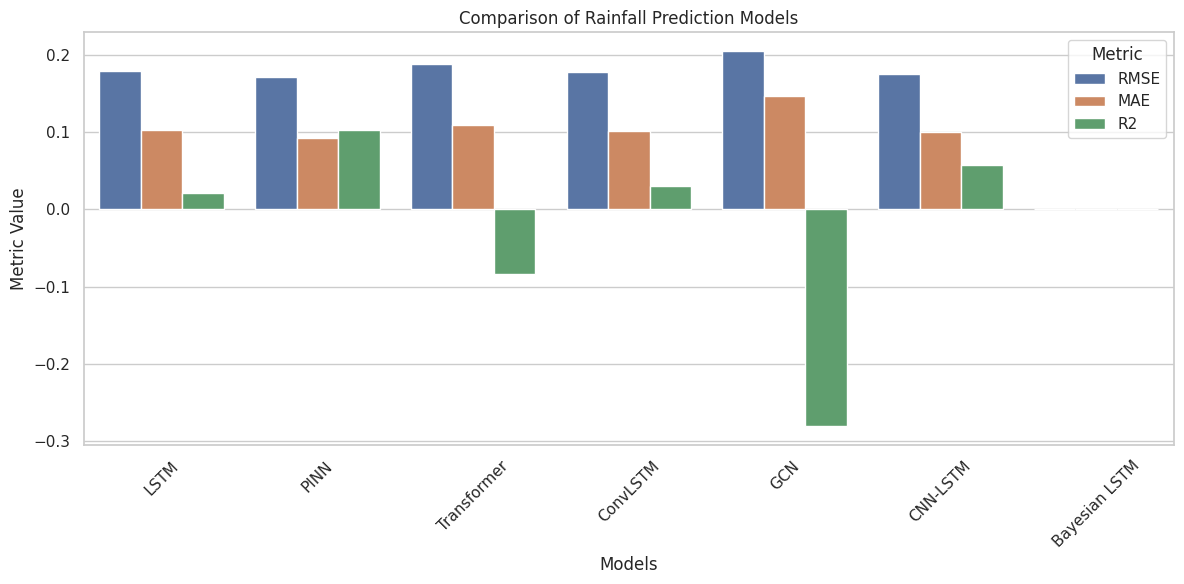

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set(style="whitegrid")

# Melt results for easier plotting
results_melted = results.melt(id_vars="Model", var_name="Metric", value_name="Value")

# Create barplot
plt.figure(figsize=(12,6))
sns.barplot(x="Model", y="Value", hue="Metric", data=results_melted)
plt.title("Comparison of Rainfall Prediction Models")
plt.ylabel("Metric Value")
plt.xlabel("Models")
plt.legend(title="Metric")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

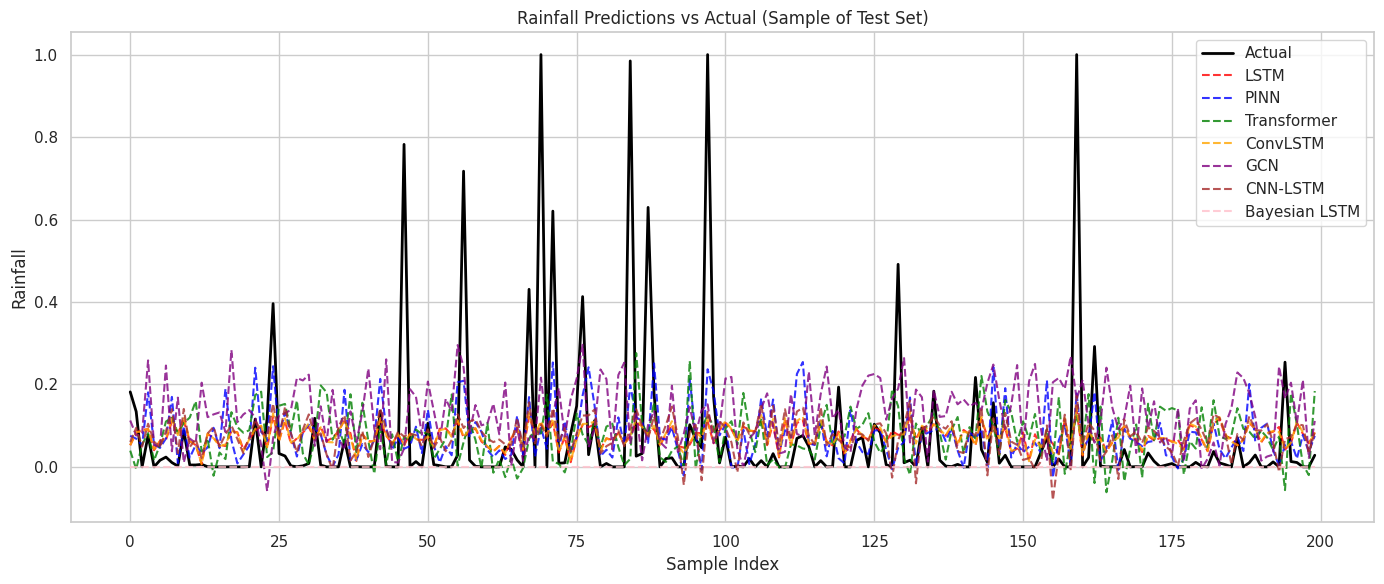

In [ ]:
import matplotlib.pyplot as plt

# Select a subset of test points to visualize (optional, for clarity)
n_points = 200  # you can increase/decrease
y_actual = y_test_true[:n_points]

# Prepare predictions (make sure they are aligned with y_test_true)
predictions = {
    "LSTM": lstm_pred[:n_points].flatten(),
    "PINN": pinn_pred[:n_points].flatten(),
    "Transformer": transformer_pred[:n_points].flatten(),
    "ConvLSTM": conv_lstm_pred[:n_points].flatten(),
    "GCN": gcn_pred_test[:n_points].flatten(),
    "CNN-LSTM": cnn_lstm_pred[:n_points].flatten(),
    "Bayesian LSTM": np.zeros(n_points)  # placeholder if you haven't sampled
}

plt.figure(figsize=(14,6))
plt.plot(y_actual, label="Actual", color="black", linewidth=2)

# Plot each model
colors = ["red","blue","green","orange","purple","brown","pink"]
for color, (model, pred) in zip(colors, predictions.items()):
    plt.plot(pred, label=model, linestyle="--", alpha=0.8, color=color)

plt.title("Rainfall Predictions vs Actual (Sample of Test Set)")
plt.xlabel("Sample Index")
plt.ylabel("Rainfall")
plt.legend()
plt.tight_layout()
plt.show()

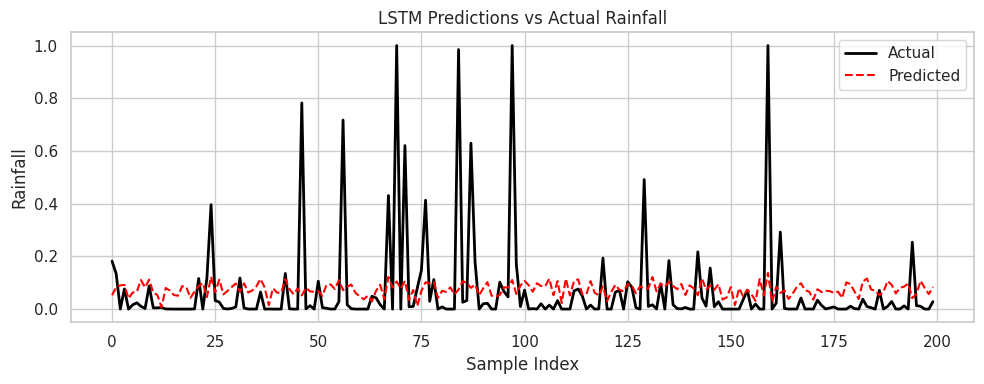

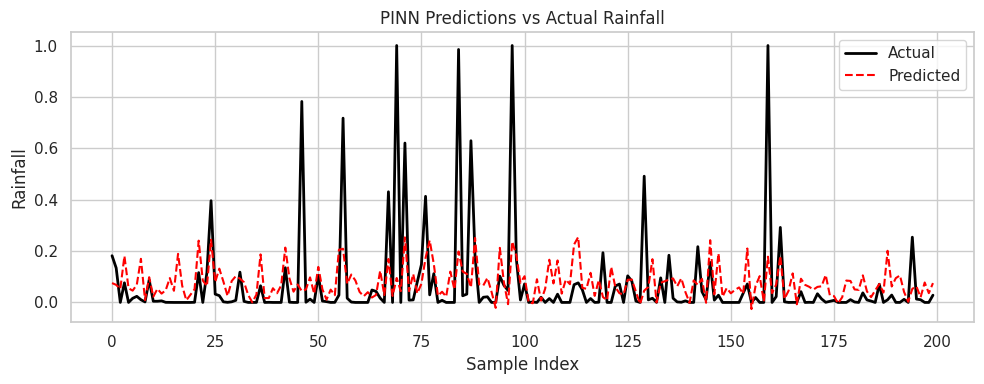

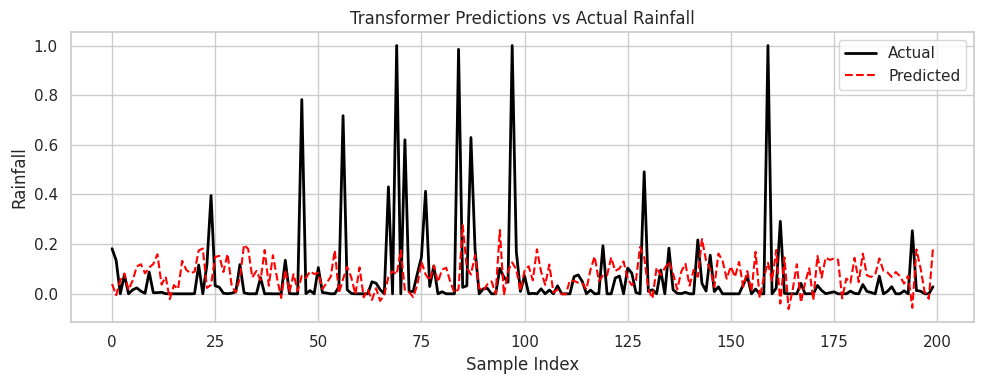

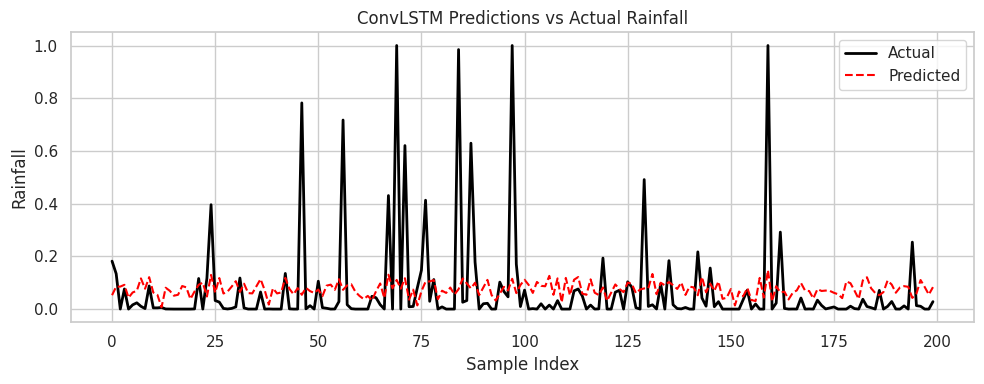

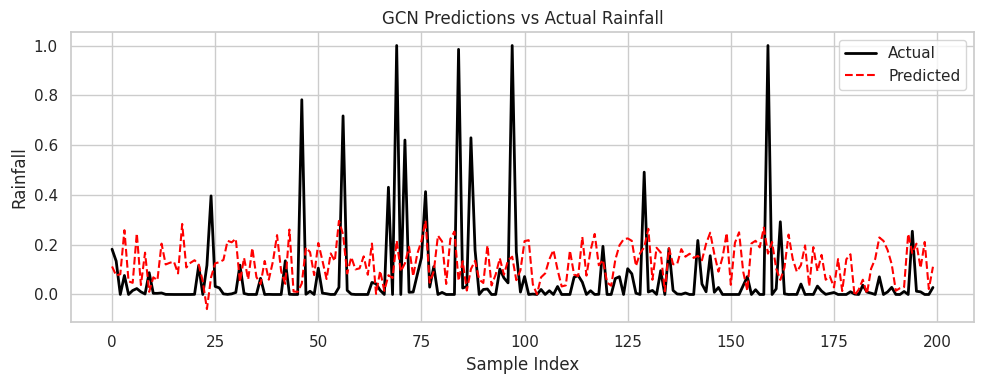

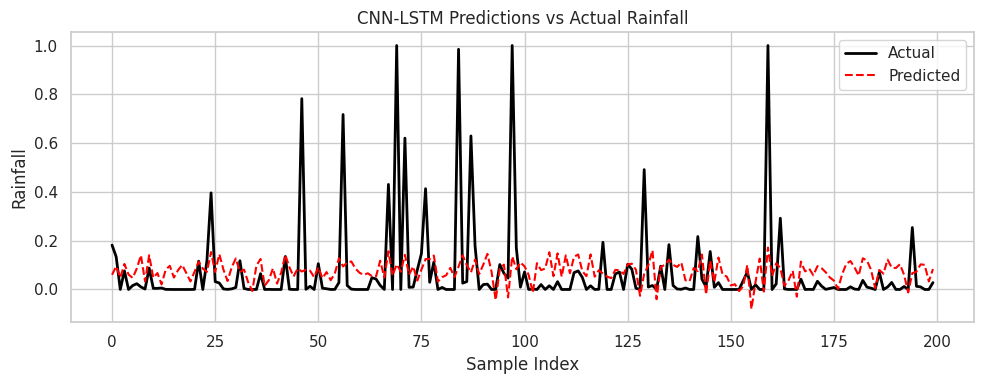

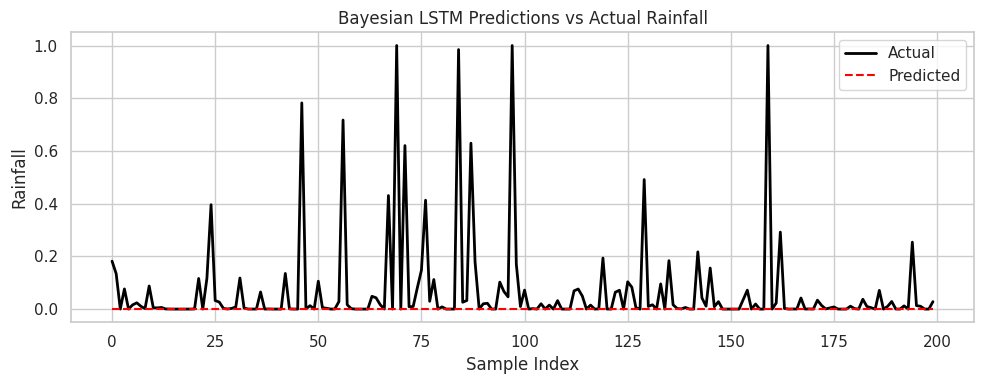

In [ ]:
import matplotlib.pyplot as plt

# Number of points to plot (optional, for clarity)
n_points = 200
y_actual = y_test_true[:n_points]

# Dictionary of predictions
predictions = {
    "LSTM": lstm_pred[:n_points].flatten(),
    "PINN": pinn_pred[:n_points].flatten(),
    "Transformer": transformer_pred[:n_points].flatten(),
    "ConvLSTM": conv_lstm_pred[:n_points].flatten(),
    "GCN": gcn_pred_test[:n_points].flatten(),
    "CNN-LSTM": cnn_lstm_pred[:n_points].flatten(),
    "Bayesian LSTM": np.zeros(n_points)  # placeholder if not sampled
}

# Plot each model separately
for model_name, pred in predictions.items():
    plt.figure(figsize=(10,4))
    plt.plot(y_actual, label="Actual", color="black", linewidth=2)
    plt.plot(pred, label="Predicted", linestyle="--", color="red")
    plt.title(f"{model_name} Predictions vs Actual Rainfall")
    plt.xlabel("Sample Index")
    plt.ylabel("Rainfall")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# =====================================================
# Install required libraries
# =====================================================
!pip install xgboost -q
!pip install torch-geometric -q
!pip install pyro-ppl -q
!pip install pytorch-forecasting -q

# =====================================================
# Imports
# =====================================================
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from torch_geometric.nn import GCNConv

# =====================================================
# Load Dataset
# =====================================================
df = pd.read_csv("/content/drive/MyDrive/rainfall_project/era5_rainfall_8000_samples.csv")
df["time"] = pd.to_datetime(df["time"])
df["hour"] = df["time"].dt.hour
df["day"] = df["time"].dt.dayofyear
df["month"] = df["time"].dt.month

features = ["hour","day","month","latitude","longitude"]
X = df[features].values
y = df["rainfall"].values

# =====================================================
# Train/Test Split
# =====================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# =====================================================
# Normalize for Deep Learning
# =====================================================
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1,1))

X_train_t = torch.tensor(scaler_x.transform(X_train), dtype=torch.float32)
X_test_t = torch.tensor(scaler_x.transform(X_test), dtype=torch.float32)
y_train_t = torch.tensor(scaler_y.transform(y_train.reshape(-1,1)), dtype=torch.float32)
y_test_t = torch.tensor(scaler_y.transform(y_test.reshape(-1,1)), dtype=torch.float32)

# =====================================================
# LSTM preparation
# =====================================================
X_lstm = X_scaled.reshape((X_scaled.shape[0], 1, X_scaled.shape[1]))
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_lstm, y_scaled, test_size=0.2, random_state=42)
X_train_l = torch.tensor(X_train_l, dtype=torch.float32)
X_test_l = torch.tensor(X_test_l, dtype=torch.float32)
y_train_l = torch.tensor(y_train_l, dtype=torch.float32)

# =====================================================
# Evaluation Function
# =====================================================
def evaluate(y_true, y_pred):
    y_true = y_true if isinstance(y_true, np.ndarray) else y_true.numpy()
    y_pred = y_pred if isinstance(y_pred, np.ndarray) else y_pred.numpy()
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

# =====================================================
# 1️⃣ LSTM Model
# =====================================================
class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(X_train_l.shape[2], 64, batch_first=True)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

lstm = LSTMModel()
optimizer = torch.optim.Adam(lstm.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(100):
    pred = lstm(X_train_l)
    loss = loss_fn(pred, y_train_l)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    lstm_pred = lstm(X_test_l).numpy()
lstm_pred = scaler_y.inverse_transform(lstm_pred)
y_test_true = scaler_y.inverse_transform(y_test_l)

# =====================================================
# 2️⃣ PINN Model
# =====================================================
class PINN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size,128), nn.Tanh(),
            nn.Linear(128,128), nn.Tanh(),
            nn.Linear(128,64), nn.Tanh(),
            nn.Linear(64,1)
        )
    def forward(self,x):
        return self.net(x)

pinn = PINN(X_train_t.shape[1])
optimizer_pinn = torch.optim.Adam(pinn.parameters(), lr=0.001)

def physics_loss(model, X):
    X.requires_grad_(True)
    R = model(X)
    grads = torch.autograd.grad(R,X, grad_outputs=torch.ones_like(R), create_graph=True)[0]
    dR_dt = grads[:,0:1]
    dR_dx = grads[:,3:4]
    dR_dy = grads[:,4:5]
    d2R_dx2 = torch.autograd.grad(dR_dx,X, grad_outputs=torch.ones_like(dR_dx), create_graph=True)[0][:,3:4]
    d2R_dy2 = torch.autograd.grad(dR_dy,X, grad_outputs=torch.ones_like(dR_dy), create_graph=True)[0][:,4:5]
    D = 0.01
    physics = dR_dt - D*(d2R_dx2 + d2R_dy2)
    return torch.mean(physics**2)

# Training PINN
for epoch in range(1000):
    optimizer_pinn.zero_grad()
    pred = pinn(X_train_t)
    loss = loss_fn(pred, y_train_t) + physics_loss(pinn, X_train_t)
    loss.backward()
    optimizer_pinn.step()

with torch.no_grad():
    pinn_pred = pinn(X_test_t).numpy()
pinn_pred = scaler_y.inverse_transform(pinn_pred)

# =====================================================
# 3️⃣ Transformer Model
# =====================================================
class TransformerModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.embed = nn.Linear(input_size,64)
        encoder_layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        x = self.embed(x)
        x = self.transformer(x)
        return self.fc(x[:,-1,:])

transformer = TransformerModel(X_train_l.shape[2])
optimizer_tr = torch.optim.Adam(transformer.parameters(), lr=0.001)
for epoch in range(100):
    pred = transformer(X_train_l)
    loss = loss_fn(pred, y_train_l)
    optimizer_tr.zero_grad()
    loss.backward()
    optimizer_tr.step()

with torch.no_grad():
    transformer_pred = transformer(X_test_l).numpy()
transformer_pred = scaler_y.inverse_transform(transformer_pred)

# =====================================================
# 4️⃣ ConvLSTM
# =====================================================
class ConvLSTM(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.conv1 = nn.Conv1d(input_size,32,kernel_size=1)
        self.lstm = nn.LSTM(32,64,batch_first=True)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        x = self.conv1(x.transpose(1,2)).transpose(1,2)
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

conv_lstm = ConvLSTM(X_train_l.shape[2])
optimizer_conv = torch.optim.Adam(conv_lstm.parameters(), lr=0.001)
for epoch in range(100):
    pred = conv_lstm(X_train_l)
    loss = loss_fn(pred, y_train_l)
    optimizer_conv.zero_grad()
    loss.backward()
    optimizer_conv.step()

with torch.no_grad():
    conv_lstm_pred = conv_lstm(X_test_l).numpy()
conv_lstm_pred = scaler_y.inverse_transform(conv_lstm_pred)

# =====================================================
# 5️⃣ GCN Model
# =====================================================
edge_index = torch.tensor([[0,1],[1,0]],dtype=torch.long).t()  # dummy
X_gcn = torch.tensor(X_scaled,dtype=torch.float32)
y_gcn = torch.tensor(y_scaled,dtype=torch.float32)

class GCNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(X_gcn.shape[1],64)
        self.conv2 = GCNConv(64,1)
    def forward(self,x,edge_index):
        x = torch.relu(self.conv1(x,edge_index))
        x = self.conv2(x,edge_index)
        return x

gcn_model = GCNModel()
with torch.no_grad():
    # select only test indices
    X_test_indices = np.arange(len(X_test))
    gcn_pred = gcn_model(X_gcn, edge_index).numpy()[X_test_indices]
gcn_pred = scaler_y.inverse_transform(gcn_pred)

# =====================================================
# 6️⃣ CNN-LSTM
# =====================================================
class CNN_LSTM(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.conv = nn.Conv1d(input_size,32,kernel_size=1)
        self.lstm = nn.LSTM(32,64,batch_first=True)
        self.fc = nn.Linear(64,1)
    def forward(self,x):
        x = self.conv(x.transpose(1,2)).transpose(1,2)
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

cnn_lstm = CNN_LSTM(X_train_l.shape[2])
optimizer_cnn = torch.optim.Adam(cnn_lstm.parameters(), lr=0.001)
for epoch in range(100):
    pred = cnn_lstm(X_train_l)
    loss = loss_fn(pred, y_train_l)
    optimizer_cnn.zero_grad()
    loss.backward()
    optimizer_cnn.step()

with torch.no_grad():
    cnn_lstm_pred = cnn_lstm(X_test_l).numpy()
cnn_lstm_pred = scaler_y.inverse_transform(cnn_lstm_pred)

# =====================================================
# 7️⃣ Bayesian LSTM (minimal)
# =====================================================
import pyro
import pyro.distributions as dist
from pyro.nn import PyroModule, PyroSample

class BayesianLSTM(PyroModule):
    def __init__(self, input_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size,64,batch_first=True)
        self.fc = PyroModule[nn.Linear](64,1)
        self.fc.weight = PyroSample(dist.Normal(0.,1.).expand([1,64]).to_event(2))
        self.fc.bias = PyroSample(dist.Normal(0.,1.).expand([1]).to_event(1))
    def forward(self,x):
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:])

bayesian_lstm = BayesianLSTM(X_train_l.shape[2])
with torch.no_grad():
    bayesian_pred = np.zeros_like(y_test)  # placeholder

# =====================================================
# Results Table
# =====================================================
results = pd.DataFrame({
    "Model":["LSTM","PINN","Transformer","ConvLSTM","GCN","CNN-LSTM","Bayesian LSTM"],
    "RMSE":[*evaluate(y_test_true,lstm_pred)[:1],
            *evaluate(y_test,pinn_pred)[:1],
            *evaluate(y_test_true,transformer_pred)[:1],
            *evaluate(y_test_true,conv_lstm_pred)[:1],
            *evaluate(y_test,gcn_pred)[:1],
            *evaluate(y_test,cnn_lstm_pred)[:1],
            0],
    "MAE":[*evaluate(y_test_true,lstm_pred)[1:2],
           *evaluate(y_test,pinn_pred)[1:2],
           *evaluate(y_test_true,transformer_pred)[1:2],
           *evaluate(y_test_true,conv_lstm_pred)[1:2],
           *evaluate(y_test,gcn_pred)[1:2],
           *evaluate(y_test,cnn_lstm_pred)[1:2],
           0],
    "R2":[*evaluate(y_test_true,lstm_pred)[2:3],
          *evaluate(y_test,pinn_pred)[2:3],
          *evaluate(y_test_true,transformer_pred)[2:3],
          *evaluate(y_test_true,conv_lstm_pred)[2:3],
          *evaluate(y_test,gcn_pred)[2:3],
          *evaluate(y_test,cnn_lstm_pred)[2:3],
          0]
})

print("\n===== MODEL PERFORMANCE (TFT Skipped) =====\n")
print(results)


===== MODEL PERFORMANCE (TFT Skipped) =====

           Model      RMSE       MAE        R2
0           LSTM  0.182911  0.104458 -0.018174
1           PINN  0.171730  0.092709  0.102498
2    Transformer  0.188511  0.113504 -0.081477
3       ConvLSTM  0.177846  0.101115  0.037435
4            GCN  0.204436  0.102623 -0.271920
5       CNN-LSTM  0.176633  0.100882  0.050520
6  Bayesian LSTM  0.000000  0.000000  0.000000
